In [9]:
# === CELL 0: Imports & basic config ===
from pathlib import Path
import shutil
import random
import os
import textwrap

import numpy as np
import cv2
import matplotlib.pyplot as plt

import torch
from ultralytics import YOLO


In [18]:
# === CELL 1: Paths & dataset parameters ===
PROJECT_ROOT = Path(r"d:\Projects\VETRA\Codes\VETRA v3.0\Training and Processing")

RAW_IMG_DIR    = PROJECT_ROOT / "udder-bottom-dataset" / "images"
RAW_LABEL_DIR  = PROJECT_ROOT / "udder-bottom-dataset" / "labels"

DATASET_ROOT   = PROJECT_ROOT / "vetra_udder_bottom_dataset"
IMG_TRAIN_DIR  = DATASET_ROOT / "images" / "train"
IMG_VAL_DIR    = DATASET_ROOT / "images" / "val"
LBL_TRAIN_DIR  = DATASET_ROOT / "labels" / "train"
LBL_VAL_DIR    = DATASET_ROOT / "labels" / "val"

DATASET_ROOT.mkdir(parents=True, exist_ok=True)
IMG_TRAIN_DIR.mkdir(parents=True, exist_ok=True)
IMG_VAL_DIR.mkdir(parents=True, exist_ok=True)
LBL_TRAIN_DIR.mkdir(parents=True, exist_ok=True)
LBL_VAL_DIR.mkdir(parents=True, exist_ok=True)

# how many copies of each image/label (simple duplication)
NUM_COPIES = 4
TRAIN_RATIO = 0.8

print("RAW_IMG_DIR:", RAW_IMG_DIR)
print("RAW_LABEL_DIR:", RAW_LABEL_DIR)
print("DATASET_ROOT:", DATASET_ROOT)


RAW_IMG_DIR: d:\Projects\VETRA\Codes\VETRA v3.0\Training and Processing\udder-bottom-dataset\images
RAW_LABEL_DIR: d:\Projects\VETRA\Codes\VETRA v3.0\Training and Processing\udder-bottom-dataset\labels
DATASET_ROOT: d:\Projects\VETRA\Codes\VETRA v3.0\Training and Processing\vetra_udder_bottom_dataset


In [19]:
# === CELL 2: Helper to build YOLO dataset (duplicate + split) ===

def build_udder_bottom_dataset(
    raw_img_dir: Path,
    raw_label_dir: Path,
    img_train_dir: Path,
    img_val_dir: Path,
    lbl_train_dir: Path,
    lbl_val_dir: Path,
    num_copies: int = 4,
    train_ratio: float = 0.8,
    image_exts=(".jpg", ".jpeg", ".png")
):
    # collect all images
    img_paths = []
    for ext in image_exts:
        img_paths.extend(sorted(raw_img_dir.glob(f"*{ext}")))
    if not img_paths:
        raise RuntimeError(f"No images found in {raw_img_dir}")

    print(f"Found {len(img_paths)} raw images.")

    # shuffle deterministically
    random.seed(42)
    random.shuffle(img_paths)

    n_train = int(len(img_paths) * train_ratio)
    train_imgs = img_paths[:n_train]
    val_imgs   = img_paths[n_train:]

    print(f"Train images: {len(train_imgs)}, Val images: {len(val_imgs)}")

    def copy_with_copies(subset_imgs, img_out_dir, lbl_out_dir):
        count = 0
        for img_path in subset_imgs:
            stem = img_path.stem
            ext  = img_path.suffix
            lbl_path = raw_label_dir / f"{stem}.txt"
            if not lbl_path.exists():
                print(f"[WARN] No label for {img_path.name}, skipping.")
                continue

            for c in range(num_copies):
                new_stem = f"{stem}_c{c}"
                new_img  = img_out_dir / f"{new_stem}{ext}"
                new_lbl  = lbl_out_dir / f"{new_stem}.txt"
                shutil.copy2(img_path, new_img)
                shutil.copy2(lbl_path, new_lbl)
                count += 1
        return count

    n_train_copies = copy_with_copies(train_imgs, IMG_TRAIN_DIR, LBL_TRAIN_DIR)
    n_val_copies   = copy_with_copies(val_imgs, IMG_VAL_DIR, LBL_VAL_DIR)

    print(f"Created {n_train_copies} train copies and {n_val_copies} val copies.")

# build the dataset
build_udder_bottom_dataset(
    RAW_IMG_DIR, RAW_LABEL_DIR,
    IMG_TRAIN_DIR, IMG_VAL_DIR,
    LBL_TRAIN_DIR, LBL_VAL_DIR,
    num_copies=NUM_COPIES,
    train_ratio=TRAIN_RATIO
)


Found 131 raw images.
Train images: 104, Val images: 27
Created 416 train copies and 108 val copies.


In [23]:
# === CELL 3: Write vetra_udder_bottom.yaml for YOLO pose ===

yaml_text = textwrap.dedent(f"""
    # VETRA – Udder bottom view (YOLO pose, 8 keypoints)
    path: {DATASET_ROOT.as_posix()}
    train: images/train
    val: images/val

    names:
      0: udder_bottom

    # 8 keypoints, with (x, y, v) format
    kpt_shape: [8, 2]
    # simple flip index (no swapping). If you want left/right swap,
    # you can edit this later.
    flip_idx: [0,1,2,3,4,5,6,7]
""").strip() + "\n"

yaml_path = DATASET_ROOT / "vetra_udder_bottom.yaml"
with open(yaml_path, "w") as f:
    f.write(yaml_text)

print("YAML written to:", yaml_path.read_text())


YAML written to: # VETRA – Udder bottom view (YOLO pose, 8 keypoints)
path: d:/Projects/VETRA/Codes/VETRA v3.0/Training and Processing/vetra_udder_bottom_dataset
train: images/train
val: images/val

names:
  0: udder_bottom

# 8 keypoints, with (x, y, v) format
kpt_shape: [8, 2]
# simple flip index (no swapping). If you want left/right swap,
# you can edit this later.
flip_idx: [0,1,2,3,4,5,6,7]



In [25]:
cache_train = DATASET_ROOT / "labels" / "train.cache"
cache_val   = DATASET_ROOT / "labels" / "val.cache"

for c in [cache_train, cache_val]:
    if c.exists():
        c.unlink()
        print("Deleted cache:", c)
    else:
        print("No cache found:", c)


Deleted cache: d:\Projects\VETRA\Codes\VETRA v3.0\Training and Processing\vetra_udder_bottom_dataset\labels\train.cache
No cache found: d:\Projects\VETRA\Codes\VETRA v3.0\Training and Processing\vetra_udder_bottom_dataset\labels\val.cache


In [26]:
# === CELL 4: Training config ===

CONFIG = {
    "base_model": "yolov8n-pose.pt",  # pose nano as base
    "epochs": 80,
    "imgsz": 512,
    "batch_size": 16,
    "patience": 20,
}

def train_udder_bottom_yolo(yaml_file: Path):
    print("\n🎯 STARTING YOLO POSE TRAINING FOR UDDER BOTTOM VIEW")
    print("=" * 60)

    device = "0" if torch.cuda.is_available() else "cpu"
    print("Using device:", device)

    # safer cuDNN settings on low VRAM
    torch.backends.cudnn.benchmark = False
    torch.backends.cudnn.deterministic = True

    model = YOLO(CONFIG["base_model"])

    results = model.train(
        data=str(yaml_file),
        epochs=CONFIG["epochs"],
        imgsz=CONFIG["imgsz"],
        batch=CONFIG["batch_size"],
        project="runs/udder_bottom_view",
        name="yolo_pose_udder_bottom_v1",
        patience=CONFIG["patience"],
        save=True,
        exist_ok=True,
        workers=0,
        device=device,
        amp=False,      # avoid cuDNN workspace issues
        verbose=True,
    )

    print("✅ UDDER BOTTOM training completed.")
    print("Results dir:", results.save_dir)
    print("Best weights:", results.save_dir / "weights" / "best.pt")
    return model, results

udder_model, udder_results = train_udder_bottom_yolo(yaml_path)



🎯 STARTING YOLO POSE TRAINING FOR UDDER BOTTOM VIEW
Using device: 0
New https://pypi.org/project/ultralytics/8.3.235 available  Update with 'pip install -U ultralytics'
Ultralytics 8.3.203  Python-3.11.3 torch-2.6.0+cu124 CUDA:0 (NVIDIA GeForce RTX 3050 Ti Laptop GPU, 4096MiB)
engine\trainer: agnostic_nms=False, amp=False, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=d:\Projects\VETRA\Codes\VETRA v3.0\Training and Processing\vetra_udder_bottom_dataset\vetra_udder_bottom.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=80, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=512, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=

In [27]:
# === CELL 6: Keypoint names & skeleton (8 kpts) ===

UDDER_KPT_NAMES = [
    "front_left_tip",     # 0
    "front_left_base",    # 1
    "front_right_tip",    # 2
    "front_right_base",   # 3
    "rear_left_tip",      # 4
    "rear_left_base",     # 5
    "rear_right_tip",     # 6
    "rear_right_base",    # 7
]

U_name_to_idx = {n: i for i, n in enumerate(UDDER_KPT_NAMES)}
U_name_to_idx


{'front_left_tip': 0,
 'front_left_base': 1,
 'front_right_tip': 2,
 'front_right_base': 3,
 'rear_left_tip': 4,
 'rear_left_base': 5,
 'rear_right_tip': 6,
 'rear_right_base': 7}

In [28]:
# Edges to draw (tip -> base within each teat, plus a rectangle of bases)

UDDER_SKELETON_EDGES = [
    (U_name_to_idx["front_left_tip"],  U_name_to_idx["front_left_base"]),
    (U_name_to_idx["front_right_tip"], U_name_to_idx["front_right_base"]),
    (U_name_to_idx["rear_left_tip"],   U_name_to_idx["rear_left_base"]),
    (U_name_to_idx["rear_right_tip"],  U_name_to_idx["rear_right_base"]),

    # connect the four bases in order: FL -> FR -> RR -> RL -> FL
    (U_name_to_idx["front_left_base"],  U_name_to_idx["front_right_base"]),
    (U_name_to_idx["front_right_base"], U_name_to_idx["rear_right_base"]),
    (U_name_to_idx["rear_right_base"],  U_name_to_idx["rear_left_base"]),
    (U_name_to_idx["rear_left_base"],   U_name_to_idx["front_left_base"]),
]


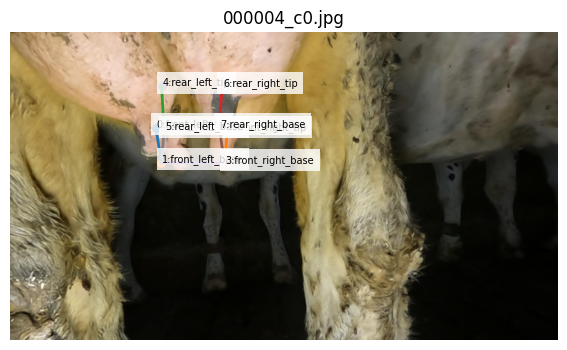

In [30]:
%matplotlib inline
# === CELL 7: Visualize udder bottom pose (YOLO) ===

def plot_udder_bottom_pose(
    img_path: Path,
    yolo_model,
    conf: float = 0.5,
    figsize=(8, 4),
):
    img_bgr = cv2.imread(str(img_path))
    if img_bgr is None:
        print("Could not read:", img_path)
        return
    img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)

    results = yolo_model(str(img_path), conf=conf, verbose=False)
    res = results[0]

    plt.figure(figsize=figsize)
    plt.imshow(img_rgb)
    plt.axis("off")

    if res.keypoints is None or len(res.keypoints) == 0:
        print("No keypoints detected.")
        plt.show()
        return

    kpts = res.keypoints.xy[0].cpu().numpy()  # (8,2)

    # draw skeleton
    for i, j in UDDER_SKELETON_EDGES:
        x1, y1 = kpts[i]
        x2, y2 = kpts[j]
        if not (np.isnan(x1) or np.isnan(y1) or np.isnan(x2) or np.isnan(y2)):
            plt.plot([x1, x2], [y1, y2], linewidth=2)

    # draw points
    for idx, (x, y) in enumerate(kpts):
        if np.isnan(x) or np.isnan(y):
            continue
        plt.scatter(x, y, s=30)
        label = f"{idx}:{UDDER_KPT_NAMES[idx]}"
        plt.text(
            x + 3, y - 3, label,
            fontsize=7,
            bbox=dict(facecolor="white", alpha=0.8, edgecolor="none")
        )

    plt.title(img_path.name)
    plt.show()


# Example usage
sample_img = next(IMG_VAL_DIR.glob("*.jpg"))  # adjust ext if needed
plot_udder_bottom_pose(sample_img, udder_model)


In [31]:
# === CELL 8: Measurement helpers (from keypoints) ===
import math

def dist(p1, p2):
    return float(np.linalg.norm(np.asarray(p1) - np.asarray(p2)))

def extract_udder_kpts_from_results(res):
    """Return (8,2) array of keypoints for the first instance, or None."""
    if res.keypoints is None or len(res.keypoints) == 0:
        return None
    return res.keypoints.xy[0].cpu().numpy()  # (K,2)


def measure_teat_lengths(kpts, pixel_per_cm: float | None = None):
    """Length of each teat (tip->base)."""
    idx = U_name_to_idx
    L_fl = dist(kpts[idx["front_left_tip"]],  kpts[idx["front_left_base"]])
    L_fr = dist(kpts[idx["front_right_tip"]], kpts[idx["front_right_base"]])
    L_rl = dist(kpts[idx["rear_left_tip"]],   kpts[idx["rear_left_base"]])
    L_rr = dist(kpts[idx["rear_right_tip"]],  kpts[idx["rear_right_base"]])

    if pixel_per_cm is not None and pixel_per_cm > 0:
        conv = lambda d: d / pixel_per_cm
    else:
        conv = lambda d: d

    return {
        "front_left":  conv(L_fl),
        "front_right": conv(L_fr),
        "rear_left":   conv(L_rl),
        "rear_right":  conv(L_rr),
    }


def measure_teat_placement_front_rear(kpts):
    """
    Return normalized placement metrics in [0,1]:

      front_closeness: 1 = very close under quarter centre, 0 = very wide
      rear_closeness:  same but for rear teats

    Uses base points and normalizes by half of udder width.
    """
    idx = U_name_to_idx

    fl = np.asarray(kpts[idx["front_left_base"]])
    fr = np.asarray(kpts[idx["front_right_base"]])
    rl = np.asarray(kpts[idx["rear_left_base"]])
    rr = np.asarray(kpts[idx["rear_right_base"]])

    # quarter centres = midpoints between front & rear base on each side
    centre_L = 0.5 * (fl + rl)
    centre_R = 0.5 * (fr + rr)

    dL_front = abs(fl[0] - centre_L[0])
    dR_front = abs(fr[0] - centre_R[0])
    dL_rear  = abs(rl[0] - centre_L[0])
    dR_rear  = abs(rr[0] - centre_R[0])

    avg_front = 0.5 * (dL_front + dR_front)
    avg_rear  = 0.5 * (dL_rear + dR_rear)

    # udder width ≈ extreme bases
    x_min = min(fl[0], fr[0], rl[0], rr[0])
    x_max = max(fl[0], fr[0], rl[0], rr[0])
    udder_half_width = max((x_max - x_min) / 2.0, 1e-6)

    # ratio 0 = perfectly under centre, 1 = at quarter edge or beyond
    r_front = min(avg_front / udder_half_width, 1.0)
    r_rear  = min(avg_rear  / udder_half_width, 1.0)

    # convert to "closeness": 1 = close, 0 = wide
    front_closeness = 1.0 - r_front
    rear_closeness  = 1.0 - r_rear

    return {
        "front_closeness": front_closeness,
        "rear_closeness":  rear_closeness,
    }


In [32]:
# === CELL 9: ATC scoring for teat traits (1–9) ===

def clamp(v, vmin, vmax):
    return max(vmin, min(vmax, v))

def score_from_range(value, lo, hi, reverse=False):
    """
    Map value in [lo,hi] to score in [1,9].
      reverse=False: lo→1, mid→5, hi→9
      reverse=True:  lo→9, hi→1
    """
    if lo == hi:
        return 5.0
    t = (value - lo) / (hi - lo)
    t = clamp(t, 0.0, 1.0)
    if reverse:
        t = 1.0 - t
    return 1.0 + 8.0 * t


def score_teat_length(length_cm: float,
                      species: str = "cattle",
                      min_cm: float = 3.0,
                      max_cm: float = 9.0):
    """
    Trait 13. Teat Length (NDDB): short → long (1..9).
    You can tune min_cm/max_cm from your population stats.
    """
    return score_from_range(length_cm, min_cm, max_cm, reverse=False)


def score_front_teat_placement(front_closeness: float):
    """
    Trait 12. Front Teat Placement: wide (1) .. close (9).
    We already converted to 'closeness' in [0,1].
    """
    front_closeness = clamp(front_closeness, 0.0, 1.0)
    return 1.0 + 8.0 * front_closeness


def score_rear_teat_placement(rear_closeness: float):
    """
    Trait 17. Rear Teat Placement: wide (1) .. close (9).
    """
    rear_closeness = clamp(rear_closeness, 0.0, 1.0)
    return 1.0 + 8.0 * rear_closeness


def score_teat_thickness(thickness_cm: float,
                         min_cm: float = 1.0,
                         max_cm: float = 3.0):
    """
    Trait 19. Teat Thickness: thin (1) .. thick (9).
    Here thickness_cm should be ~diameter at mid-teat.
    The actual thickness measurement can come from:
      - a dedicated segmentation/width estimator around the teat, or
      - manual input + scaling engine.
    """
    return score_from_range(thickness_cm, min_cm, max_cm, reverse=False)


In [33]:
# === CELL 10: End-to-end trait scoring from one image ===

def analyse_udder_bottom_image(
    img_path: Path,
    yolo_model,
    pixel_per_cm: float | None = None,
    species: str = "cattle",           # or "buffalo"
    conf: float = 0.5,
):
    results = yolo_model(str(img_path), conf=conf, verbose=False)
    res = results[0]
    kpts = extract_udder_kpts_from_results(res)
    if kpts is None:
        raise RuntimeError("No udder instance detected in image.")

    # 1) measure in px/cm
    lengths = measure_teat_lengths(kpts, pixel_per_cm=pixel_per_cm)
    placements = measure_teat_placement_front_rear(kpts)

    # choose which teat to use for official "Teat Length" and "Teat Thickness"
    if species.lower() == "buffalo":
        ref_teat = "rear_left"   # guideline: left rear for buffalo
    else:
        ref_teat = "front_left"  # guideline: left front for cattle

    teat_length_val = lengths[ref_teat]  # px or cm depending on scale

    # If pixel_per_cm is None, treat 'length' units as "pseudo-cm"
    if pixel_per_cm is None:
        # you can later calibrate to real cm using dataset stats
        length_cm_for_score = teat_length_val
    else:
        length_cm_for_score = teat_length_val

    # thickness: here we assume you have some estimate in cm.
    # For now we’ll just approximate thickness as length * 0.2 (placeholder).
    teat_thickness_cm_est = 0.2 * length_cm_for_score

    # 2) scores
    scores = {
        "teat_length": float(score_teat_length(length_cm_for_score,
                                              species=species)),
        "front_teat_placement": float(score_front_teat_placement(
            placements["front_closeness"]
        )),
        "rear_teat_placement": float(score_rear_teat_placement(
            placements["rear_closeness"]
        )),
        "teat_thickness": float(score_teat_thickness(teat_thickness_cm_est)),
    }

    return {
        "lengths": lengths,
        "placements": placements,
        "teat_length_cm_for_score": length_cm_for_score,
        "teat_thickness_cm_est": teat_thickness_cm_est,
        "scores": scores,
    }


# Example usage on one val image (using relative units, no scale)
sample_img = next(IMG_VAL_DIR.glob("*.jpg"))
result = analyse_udder_bottom_image(
    sample_img,
    udder_model,
    pixel_per_cm=None,   # plug scaling-engine value here
    species="cattle",
)

print("Image:", sample_img.name)
print("Raw lengths:", result["lengths"])
print("Placement closeness:", result["placements"])
print("Scores (1–9):")
for k, v in result["scores"].items():
    print(f"  {k}: {v:.2f}")


Image: 000004_c0.jpg
Raw lengths: {'front_left': 124.0945053100586, 'front_right': 115.76680755615234, 'rear_left': 154.70846557617188, 'rear_right': 143.27999877929688}
Placement closeness: {'front_closeness': np.float32(0.93623364), 'rear_closeness': np.float32(0.93623364)}
Scores (1–9):
  teat_length: 9.00
  front_teat_placement: 8.49
  rear_teat_placement: 8.49
  teat_thickness: 9.00


In [34]:
import numpy as np

def clamp(x, lo, hi):
    return float(max(lo, min(hi, x)))


def linear_score_1_to_9(val, vmin, vmax, higher_is_better=True):
    """
    Map a measurement in [vmin, vmax] to [1,9].
    If val is outside [vmin, vmax], it will be clipped before scoring.
    """
    if vmax <= vmin:
        return 5.0  # fallback
    val = clamp(val, vmin, vmax)
    norm = (val - vmin) / (vmax - vmin)  # 0..1
    score = 1.0 + 8.0 * norm             # 1..9
    if not higher_is_better:
        score = 10.0 - score             # flip: big val -> low score
    return score


def compute_teat_metrics_and_scores(
    raw_lengths: dict,
    placement_closeness: dict,
    cm_per_pixel: float = None,
    # length limits in same unit you score with (px or cm)
    len_min: float = None,
    len_max: float = None,
    length_use_front_only: bool = True,
    # optional thickness metric and limits
    thickness_measure: float = None,
    thickness_min: float = None,
    thickness_max: float = None,
    # set True if you want scores quantized to {1, 5, 9}
    discrete_1_5_9: bool = False,
):
    """
    raw_lengths example:
        {
          "front_left": 124.1,
          "front_right": 115.8,
          "rear_left": 154.7,
          "rear_right": 143.3,
        }

    placement_closeness example:
        {
          "front_closeness": 0.9362,
          "rear_closeness": 0.9362,
        }

    cm_per_pixel:
        - If given: lengths are converted to cm for scoring.
        - If None: scoring is done in pixels (then choose len_min/len_max in pixels).

    Returns a dict with:
        - 'lengths': raw & clamped, plus min/max used
        - 'placement': raw & clamped closeness
        - 'thickness': raw & clamped thickness (if provided)
        - 'scores': teat_length, front_teat_placement, rear_teat_placement, teat_thickness
    """
    # -------- 1) Prepare lengths --------
    front_vals = [raw_lengths["front_left"], raw_lengths["front_right"]]
    rear_vals = [raw_lengths["rear_left"], raw_lengths["rear_right"]]
    all_vals = front_vals + rear_vals

    if length_use_front_only:
        vals_for_length = [v for v in front_vals if v is not None]
    else:
        vals_for_length = [v for v in all_vals if v is not None]

    mean_len_px = float(np.mean(vals_for_length)) if vals_for_length else None

    if cm_per_pixel is not None and mean_len_px is not None:
        mean_len = mean_len_px * cm_per_pixel
        length_unit = "cm"
    else:
        mean_len = mean_len_px
        length_unit = "px"

    # Set default limits if not provided
    if mean_len is not None and (len_min is None or len_max is None):
        if length_unit == "cm":
            # rough teat length range; tune this for your data
            len_min = 3.0 if len_min is None else len_min
            len_max = 9.0 if len_max is None else len_max
        else:
            # rough range in pixels; tune based on your images
            len_min = 30.0 if len_min is None else len_min
            len_max = 120.0 if len_max is None else len_max

    if mean_len is not None:
        mean_len_clamped = clamp(mean_len, len_min, len_max)
        teat_length_score = linear_score_1_to_9(
            mean_len_clamped, len_min, len_max, higher_is_better=True
        )
    else:
        mean_len_clamped = None
        teat_length_score = None

    # -------- 2) Placement from closeness (0..1) --------
    fc_raw = placement_closeness.get("front_closeness", 0.5)
    rc_raw = placement_closeness.get("rear_closeness", 0.5)
    fc = clamp(float(fc_raw), 0.0, 1.0)
    rc = clamp(float(rc_raw), 0.0, 1.0)

    # 0 -> score 1 (outside), 1 -> score 9 (inside/ideal)
    front_place_score = 1.0 + 8.0 * fc
    rear_place_score = 1.0 + 8.0 * rc

    # -------- 3) Thickness (if you have a metric) --------
    if thickness_measure is not None:
        t_raw = float(thickness_measure)
        if thickness_min is None or thickness_max is None:
            # rough default around observed value; tune these
            thickness_min = t_raw * 0.5 if thickness_min is None else thickness_min
            thickness_max = t_raw * 1.5 if thickness_max is None else thickness_max
        t_clamped = clamp(t_raw, thickness_min, thickness_max)
        teat_thickness_score = linear_score_1_to_9(
            t_clamped, thickness_min, thickness_max, higher_is_better=True
        )
    else:
        t_raw = None
        t_clamped = None
        teat_thickness_score = None

    # -------- 4) Optional quantisation to {1,5,9} --------
    if discrete_1_5_9:
        def q(s):
            if s is None:
                return None
            if s <= 3.0:
                return 1.0
            elif s >= 7.0:
                return 9.0
            else:
                return 5.0

        teat_length_score = q(teat_length_score)
        front_place_score = q(front_place_score)
        rear_place_score = q(rear_place_score)
        teat_thickness_score = q(teat_thickness_score)

    # -------- 5) Pack results --------
    return {
        "lengths": {
            "unit": length_unit,
            "front_left": float(raw_lengths["front_left"]),
            "front_right": float(raw_lengths["front_right"]),
            "rear_left": float(raw_lengths["rear_left"]),
            "rear_right": float(raw_lengths["rear_right"]),
            "mean_length_raw": mean_len,
            "mean_length_clamped": mean_len_clamped,
            "len_min": len_min,
            "len_max": len_max,
        },
        "placement": {
            "front_closeness_raw": float(fc_raw),
            "rear_closeness_raw": float(rc_raw),
            "front_closeness_clamped": fc,
            "rear_closeness_clamped": rc,
        },
        "thickness": {
            "raw": t_raw,
            "clamped": t_clamped,
            "min": thickness_min if thickness_measure is not None else None,
            "max": thickness_max if thickness_measure is not None else None,
        },
        "scores": {
            "teat_length": teat_length_score,
            "front_teat_placement": front_place_score,
            "rear_teat_placement": rear_place_score,
            "teat_thickness": teat_thickness_score,
        },
    }


In [40]:
raw_lengths = {
    "front_left": 124.0945,
    "front_right": 115.7668,
    "rear_left": 154.7085,
    "rear_right": 143.2800,
}

placement_closeness = {
    "front_closeness": np.float32(0.93623364),
    "rear_closeness": np.float32(0.93623364),
}

# If you have cm_per_pixel from your ArUco scaling or manual calibration, set it here.
# For now, if you don't, leave it as None and choose len_min/len_max in pixels.
cm_per_pixel = None

result = compute_teat_metrics_and_scores(
    raw_lengths=raw_lengths,
    placement_closeness=placement_closeness,
    cm_per_pixel=cm_per_pixel,
    # example limits in pixels; TUNE THESE using your dataset:
    len_min=10.0,
    len_max=100.0,
    thickness_measure=None,      # or some numeric thickness metric
    discrete_1_5_9=True,         # set False if you want full 1–9 instead of {1,5,9}
)

print("Measured lengths:", result["lengths"])
print("Placement:", result["placement"])
print("Scores:", result["scores"])


Measured lengths: {'unit': 'px', 'front_left': 124.0945, 'front_right': 115.7668, 'rear_left': 154.7085, 'rear_right': 143.28, 'mean_length_raw': 119.93065, 'mean_length_clamped': 100.0, 'len_min': 10.0, 'len_max': 100.0}
Placement: {'front_closeness_raw': 0.936233639717102, 'rear_closeness_raw': 0.936233639717102, 'front_closeness_clamped': 0.936233639717102, 'rear_closeness_clamped': 0.936233639717102}
Scores: {'teat_length': 9.0, 'front_teat_placement': 9.0, 'rear_teat_placement': 9.0, 'teat_thickness': None}


In [38]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

def visualize_teat_measurements(
    img_path,
    teat_points,
    metrics,
    zoom_to_teats: bool = True,
    figsize=(8, 8)
):
    """
    Pretty visualization of teat measurements and ATC scores.

    Args:
      img_path: path to udder/teat image.
      teat_points: dict mapping teat names to (x, y) in image coordinates:
          {
             "front_left":  np.array([x_fl, y_fl]),
             "front_right": np.array([x_fr, y_fr]),
             "rear_left":   np.array([x_rl, y_rl]),
             "rear_right":  np.array([x_rr, y_rr]),
          }
      metrics: output of compute_teat_metrics_and_scores(...)

    It will:
      - draw the image,
      - mark each teat with a colored dot and length,
      - draw front & rear lines for placement,
      - overlay a summary ATC score box.
    """
    img_bgr = cv2.imread(str(img_path))
    if img_bgr is None:
        raise RuntimeError(f"Could not read image at {img_path}")
    img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
    H, W = img_rgb.shape[:2]

    # ---------------- colors & short labels ----------------
    colors = {
        "front_left":  "#FF6B6B",  # reddish
        "front_right": "#4ECDC4",  # teal
        "rear_left":   "#FFD166",  # yellow
        "rear_right":  "#9B5DE5",  # purple
    }
    short = {
        "front_left":  "FL",
        "front_right": "FR",
        "rear_left":   "RL",
        "rear_right":  "RR",
    }

    # Extract per-teat lengths & unit
    length_meta = metrics["lengths"]
    unit = length_meta.get("unit", "px")
    scores = metrics["scores"]
    placement = metrics["placement"]

    # ---------------- create figure ----------------
    fig, ax = plt.subplots(figsize=figsize)
    ax.imshow(img_rgb)
    ax.axis("off")

    # Optional: zoom in to region around teats
    if zoom_to_teats and teat_points:
        xs = [float(p[0]) for p in teat_points.values()]
        ys = [float(p[1]) for p in teat_points.values()]
        x_min, x_max = min(xs), max(xs)
        y_min, y_max = min(ys), max(ys)
        pad_x = 0.25 * max(10, (x_max - x_min))
        pad_y = 0.25 * max(10, (y_max - y_min))
        ax.set_xlim(max(0, x_min - pad_x), min(W, x_max + pad_x))
        # remember imshow has origin='upper' by default
        ax.set_ylim(min(H, y_max + pad_y), max(0, y_min - pad_y))

    # ---------------- draw each teat ----------------
    for name, pt in teat_points.items():
        if name not in colors:
            continue
        x, y = float(pt[0]), float(pt[1])
        c = colors[name]

        # point
        ax.scatter(
            x, y, s=80,
            color=c,
            edgecolor="black",
            linewidth=0.8,
            zorder=3
        )

        # look up corresponding length key in metrics["lengths"]
        length_key = name  # we stored raw per-teat length under same keys
        length_val = length_meta.get(length_key, None)

        if length_val is not None:
            label = f"{short[name]}: {length_val:.1f} {unit}"
        else:
            label = short[name]

        # label near teat
        ax.text(
            x + 10, y - 10,
            label,
            fontsize=9,
            color="white",
            ha="left",
            va="center",
            bbox=dict(
                facecolor=c,
                alpha=0.8,
                edgecolor="none",
                boxstyle="round,pad=0.25"
            ),
            zorder=4
        )

    # ---------------- draw pair lines for placement ----------------
    def draw_pair_line(a_name, b_name, closeness_key, label):
        if a_name not in teat_points or b_name not in teat_points:
            return
        p1 = np.array(teat_points[a_name], dtype=np.float32)
        p2 = np.array(teat_points[b_name], dtype=np.float32)
        cx = (p1[0] + p2[0]) / 2.0
        cy = (p1[1] + p2[1]) / 2.0

        closeness_raw = placement.get(closeness_key, 0.5)
        # 0..1 clamped
        closeness = max(0.0, min(1.0, float(closeness_raw)))
        # map closeness to color intensity (more green when high)
        # just simple text color coding, main visual is numeric
        ax.plot(
            [p1[0], p2[0]],
            [p1[1], p2[1]],
            color="white",
            linewidth=2.0,
            linestyle="-",
            zorder=2
        )

        ax.text(
            cx, cy + 20,
            f"{label} closeness: {closeness:.2f}",
            fontsize=9,
            color="black",
            ha="center",
            va="center",
            bbox=dict(
                facecolor="white",
                alpha=0.9,
                edgecolor="none",
                boxstyle="round,pad=0.25"
            ),
            zorder=4
        )

    draw_pair_line("front_left", "front_right", "front_closeness_clamped", "Front")
    draw_pair_line("rear_left", "rear_right", "rear_closeness_clamped", "Rear")

    # ---------------- summary score box ----------------
    summary_lines = []

    if scores.get("teat_length") is not None:
        summary_lines.append(f"Teat length: {scores['teat_length']:.1f}")
    if scores.get("front_teat_placement") is not None:
        summary_lines.append(f"Front teat placement: {scores['front_teat_placement']:.1f}")
    if scores.get("rear_teat_placement") is not None:
        summary_lines.append(f"Rear teat placement: {scores['rear_teat_placement']:.1f}")
    if scores.get("teat_thickness") is not None:
        summary_lines.append(f"Teat thickness: {scores['teat_thickness']:.1f}")

    if summary_lines:
        text = "ATC-like scores (1–9)\n" + "\n".join(summary_lines)
        ax.text(
            0.01 * W, 0.01 * H,
            text,
            fontsize=9,
            color="black",
            ha="left",
            va="top",
            bbox=dict(
                facecolor="white",
                alpha=0.90,
                edgecolor="black",
                boxstyle="round,pad=0.35"
            ),
            zorder=5,
            transform=ax.transData
        )

    ax.set_title(str(img_path))
    plt.show()
